In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn import preprocessing
%matplotlib inline

In [13]:
df = pd.read_csv('new_train.csv')
df[1:100]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,y
1,37,entrepreneur,married,university.degree,no,no,no,telephone,nov,wed,202,2,999,1,failure,no
2,78,retired,married,basic.4y,no,no,no,cellular,jul,mon,1148,1,999,0,nonexistent,yes
3,36,admin.,married,university.degree,no,yes,no,telephone,may,mon,120,2,999,0,nonexistent,no
4,59,retired,divorced,university.degree,no,no,no,cellular,jun,tue,368,2,999,0,nonexistent,no
5,29,admin.,single,university.degree,no,no,no,cellular,aug,wed,256,2,999,0,nonexistent,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,50,blue-collar,divorced,basic.9y,no,no,no,telephone,may,fri,878,3,999,0,nonexistent,no
96,40,admin.,single,high.school,no,yes,no,cellular,jun,tue,154,1,999,1,failure,no
97,48,services,married,basic.9y,unknown,no,no,cellular,may,fri,18,8,999,0,nonexistent,no
98,32,technician,married,university.degree,no,yes,yes,telephone,jul,thu,50,6,999,0,nonexistent,no


In [4]:
# student < technician < management

In [10]:
import numpy as np
import matplotlib.pyplot as plt


def plot_two_arrays(x1, x2):
    """
    نقاط x1 و x2 رو روی همون نمودار می‌کشه، هر کدوم با یه رنگ.
    """
    x1 = np.asarray(x1)
    x2 = np.asarray(x2)

    plt.figure(figsize=(8, 6))

    # نقاط x1 با رنگ آبی
    plt.scatter(range(len(x1)), x1, color='royalblue',
                s=90, edgecolors='k', zorder=3, label='x1')

    # نقاط x2 با رنگ قرمز
    plt.scatter(range(len(x2)), x2, color='tomato',
                s=90, edgecolors='k', zorder=3, label='x2')

    plt.xlabel('اندیس', fontsize=12)
    plt.ylabel('مقدار', fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [34]:
# first state

In [11]:

def historical(data):
    return pd.Series(data).value_counts().sort_index()

In [12]:
historical(df['job'])

job
admin.           8314
blue-collar      7441
entrepreneur     1160
housemaid         855
management       2345
retired          1366
self-employed    1099
services         3196
student           711
technician       5400
unemployed        798
unknown           265
Name: count, dtype: int64

In [8]:
import pandas as pd
import matplotlib.pyplot as plt


def plot_cat_vs_cat(col1, col2, df, title=None, normalize=True):
    """
    رابطه دو ستون دسته‌بندی رو با نمودار میله‌ای نشون می‌ده.
    normalize=True => نسبت (درصد) نشون بده
    """
    ct = pd.crosstab(df[col1], df[col2])
    if normalize:
        ct = ct.div(ct.sum(axis=1), axis=0)

    ax = ct.plot(kind='bar', figsize=(12, 6), edgecolor='k')
    ax.set_xlabel(col1, fontsize=12)
    ax.set_ylabel('نسبت' if normalize else 'تعداد', fontsize=12)
    ax.set_title(title or f'رابطه {col1} و {col2}', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.grid(True, axis='y', linestyle='--', alpha=0.5)
    plt.legend(title=col2)
    plt.tight_layout()
    plt.show()

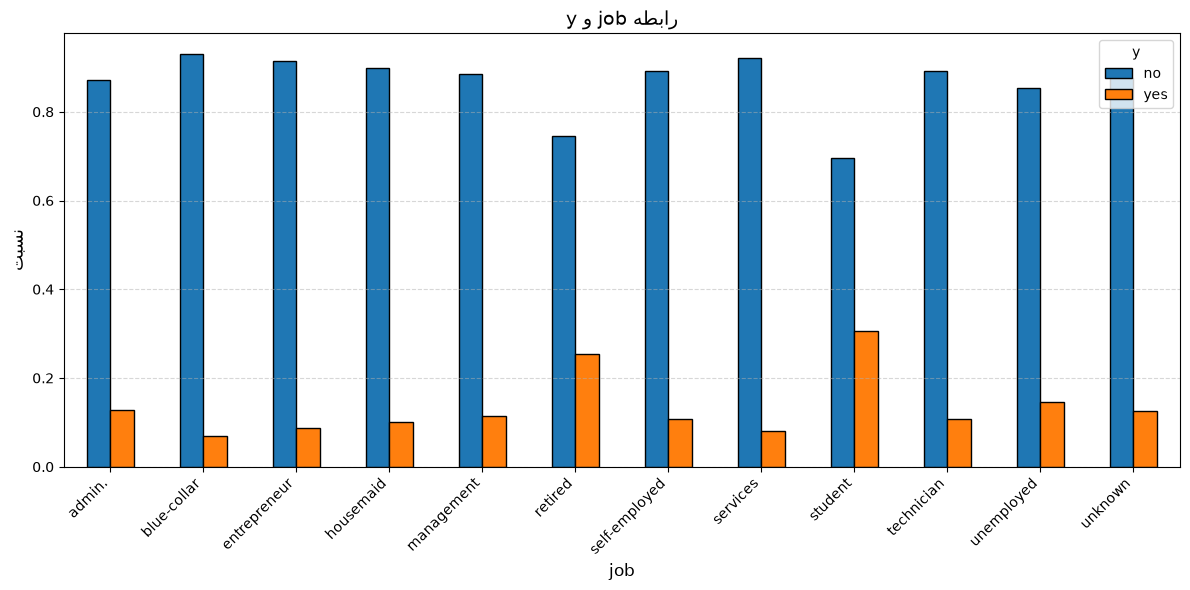

In [50]:
plot_cat_vs_cat('job', 'y', df)

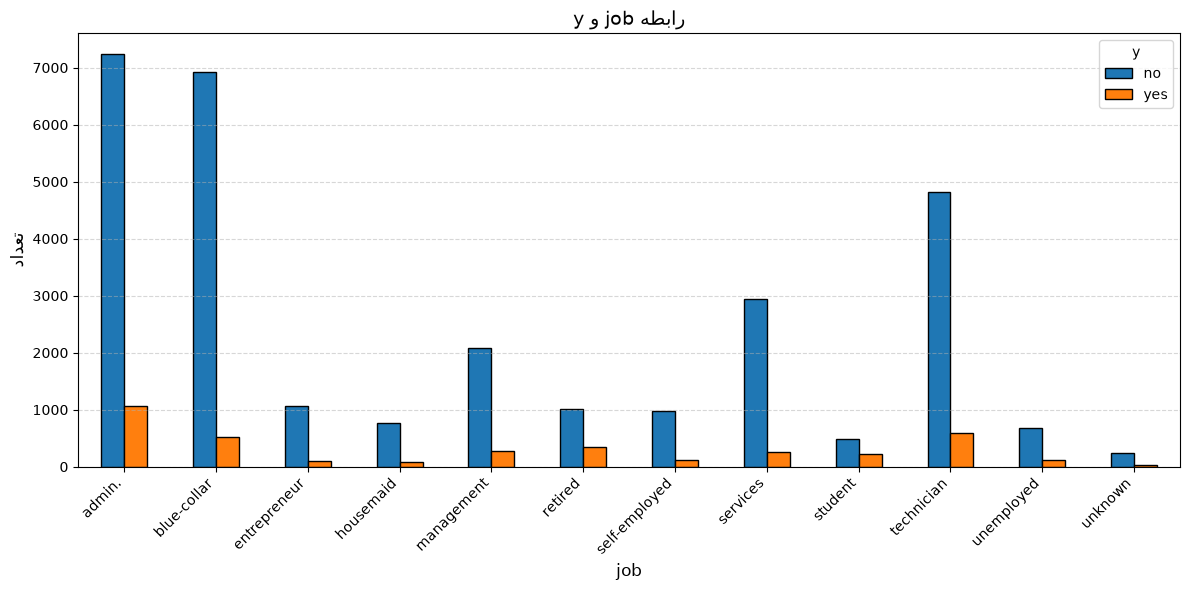

In [51]:
plot_cat_vs_cat('job', 'y', df, normalize=False)# so age is not  plot_cat_vs_cat('job', 'y', df, normalize=False)# so age is not 

In [52]:
def plot_two_arrays(a, b, df):
    # اگر هر دو عددی بودن → scatter
    if pd.api.types.is_numeric_dtype(df[a]) and pd.api.types.is_numeric_dtype(df[b]):
        plt.figure(figsize=(8, 6))
        plt.scatter(df[a], df[b], color='royalblue', s=60, edgecolors='k')
        plt.xlabel(a); plt.ylabel(b)
        plt.tight_layout(); plt.show()
    # اگر دسته‌بندی بودن → bar chart از crosstab
    else:
        plot_cat_vs_cat(a, b, df)

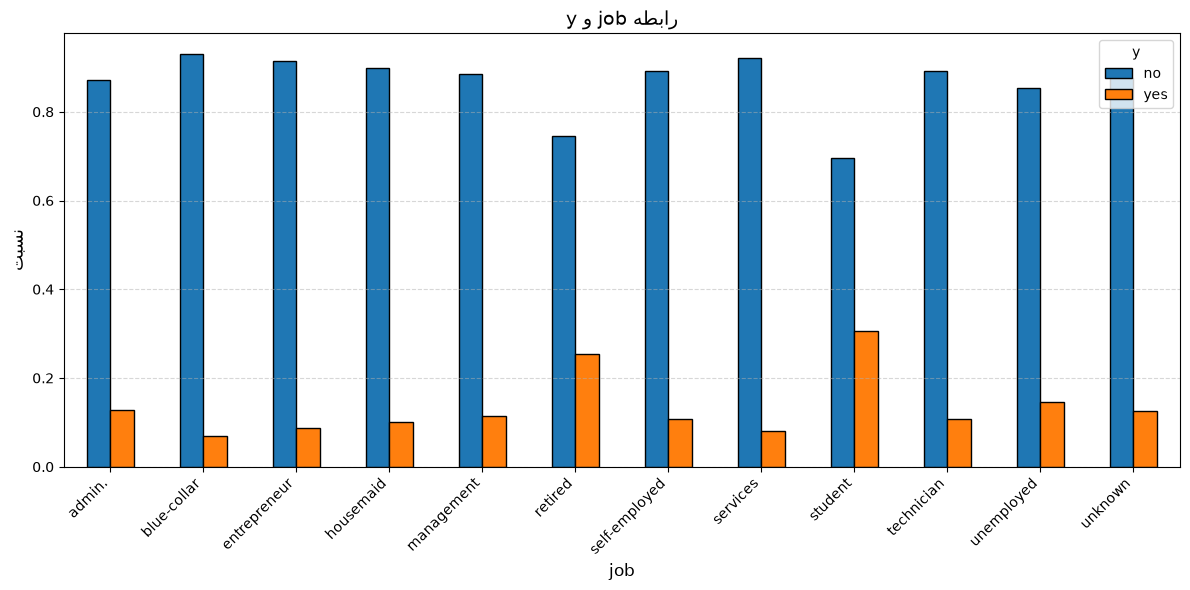

In [55]:
plot_two_arrays('job', 'y', df)

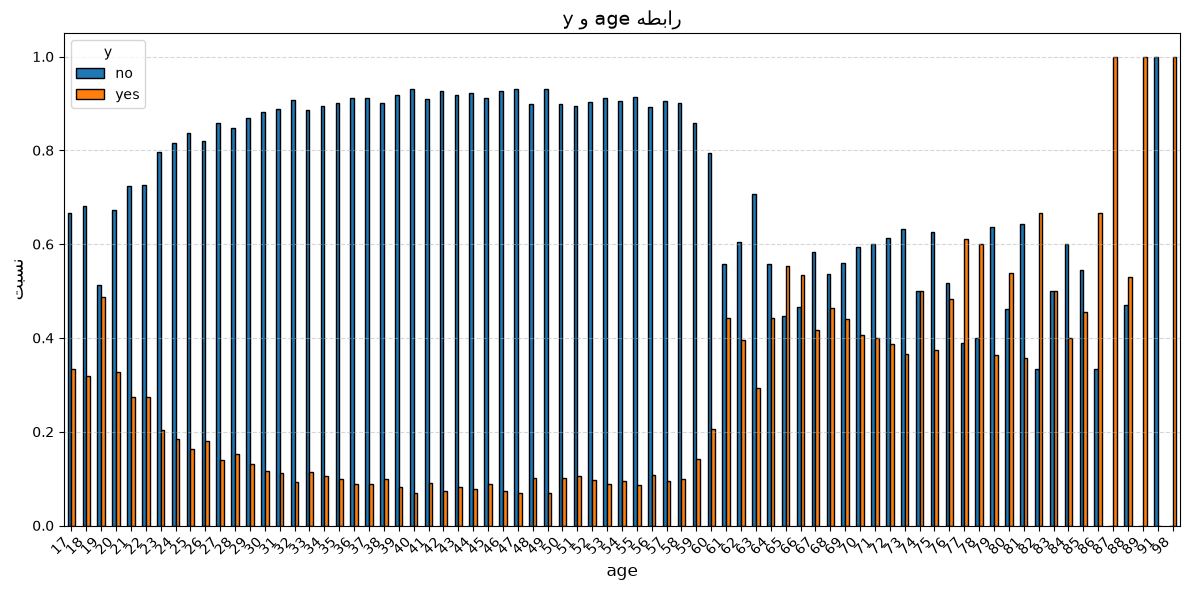

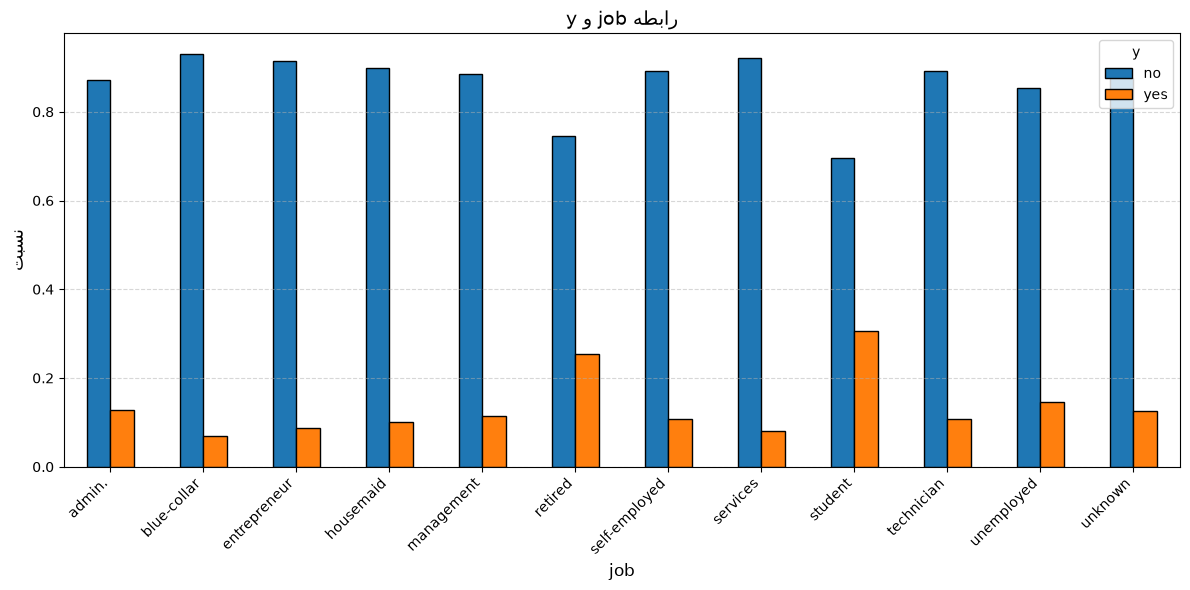

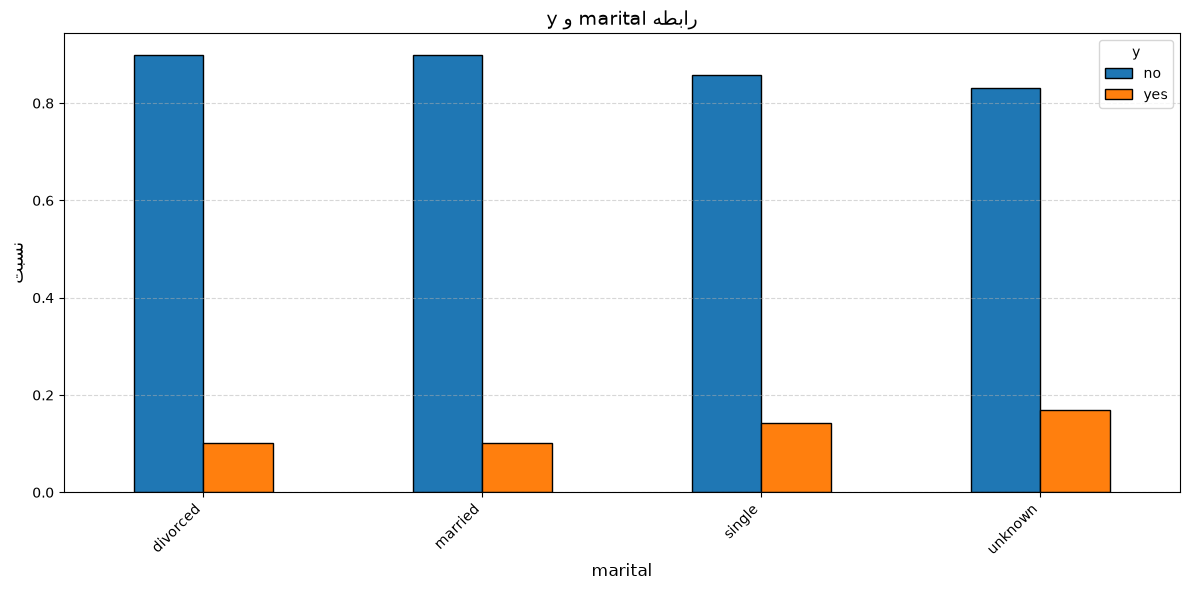

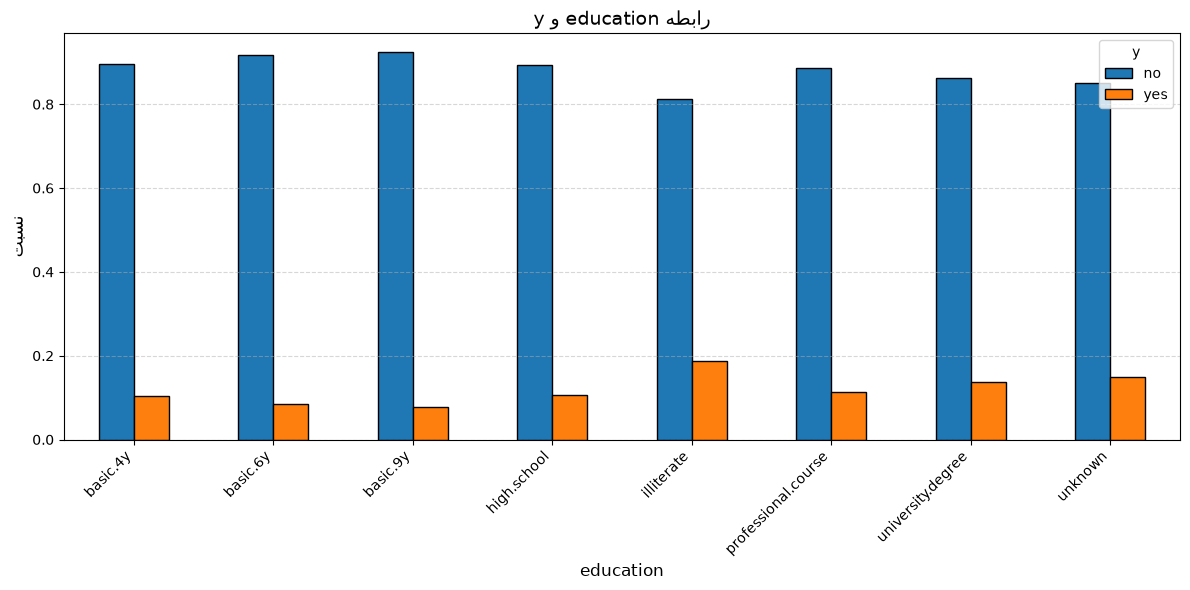

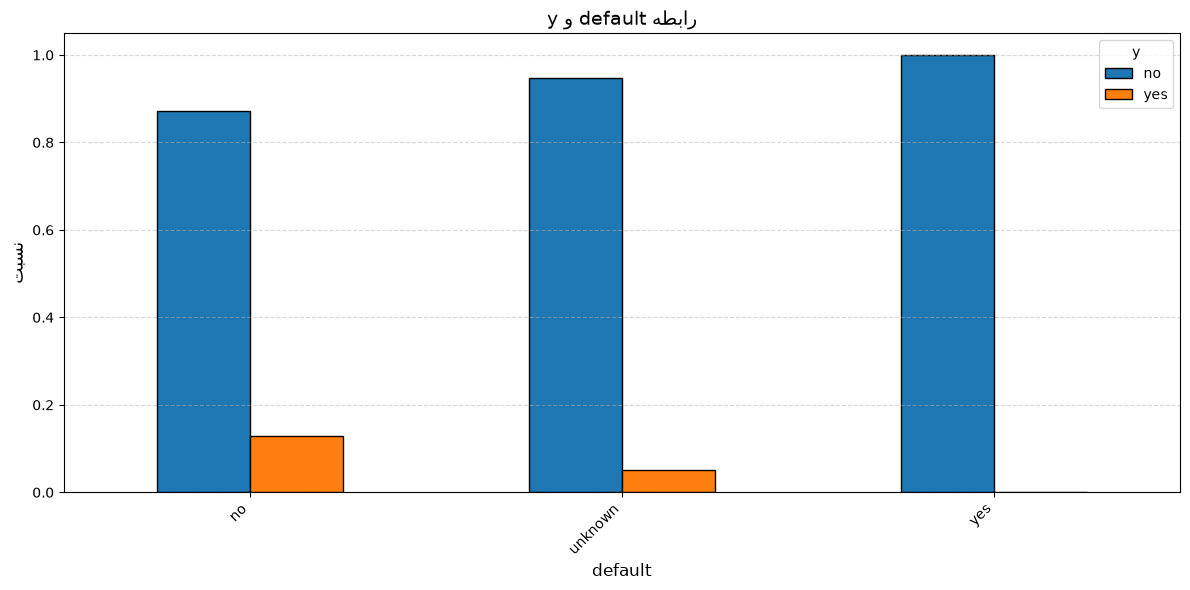

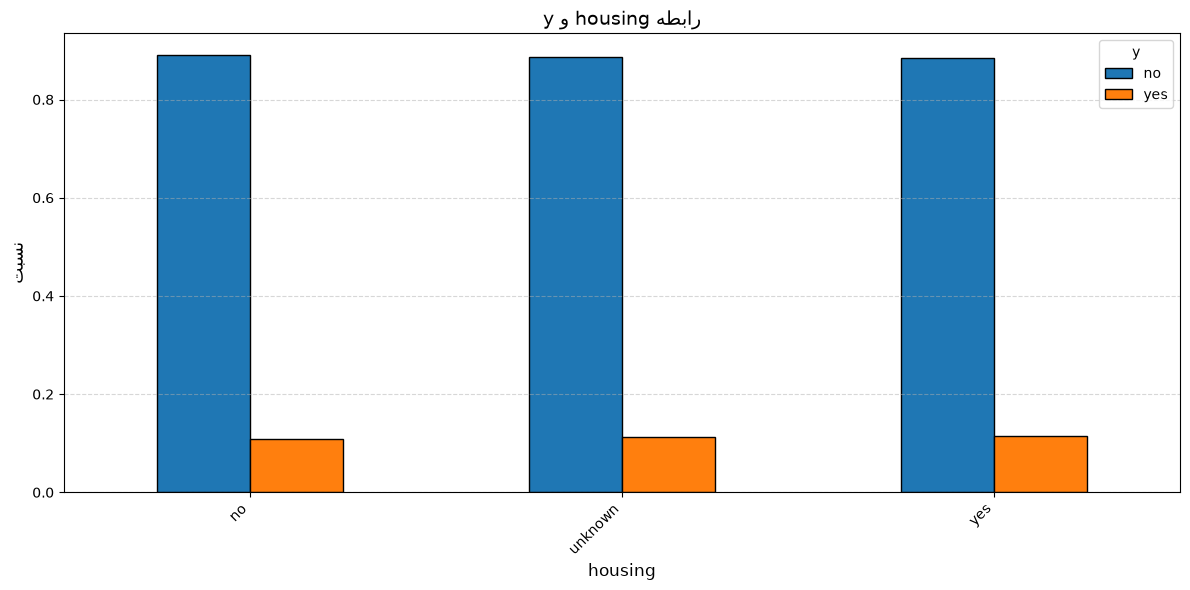

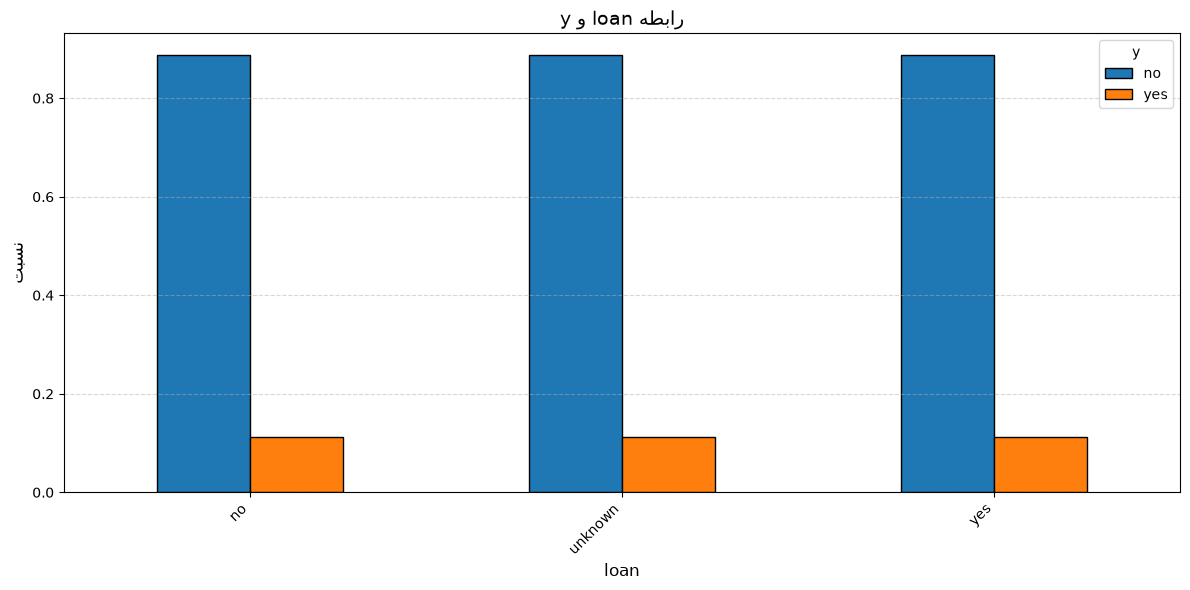

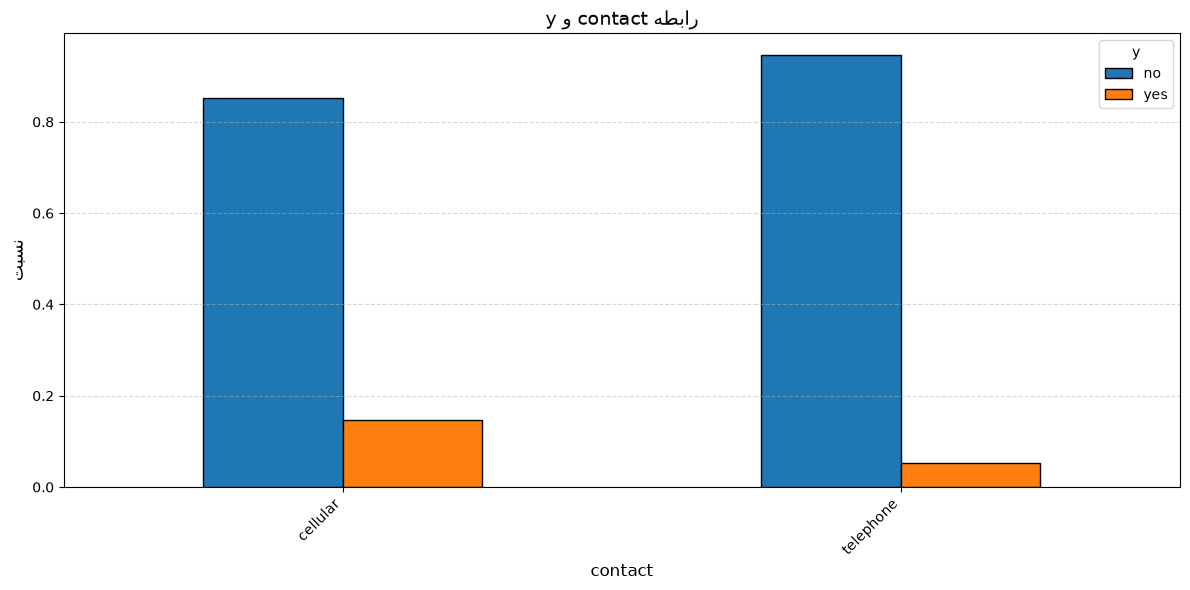

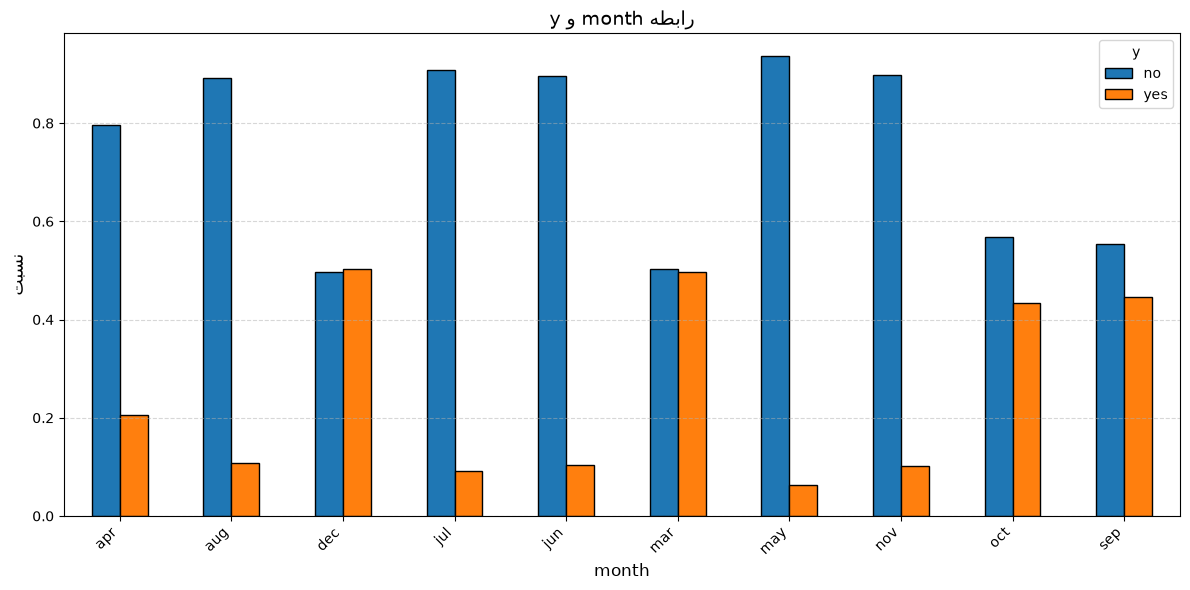

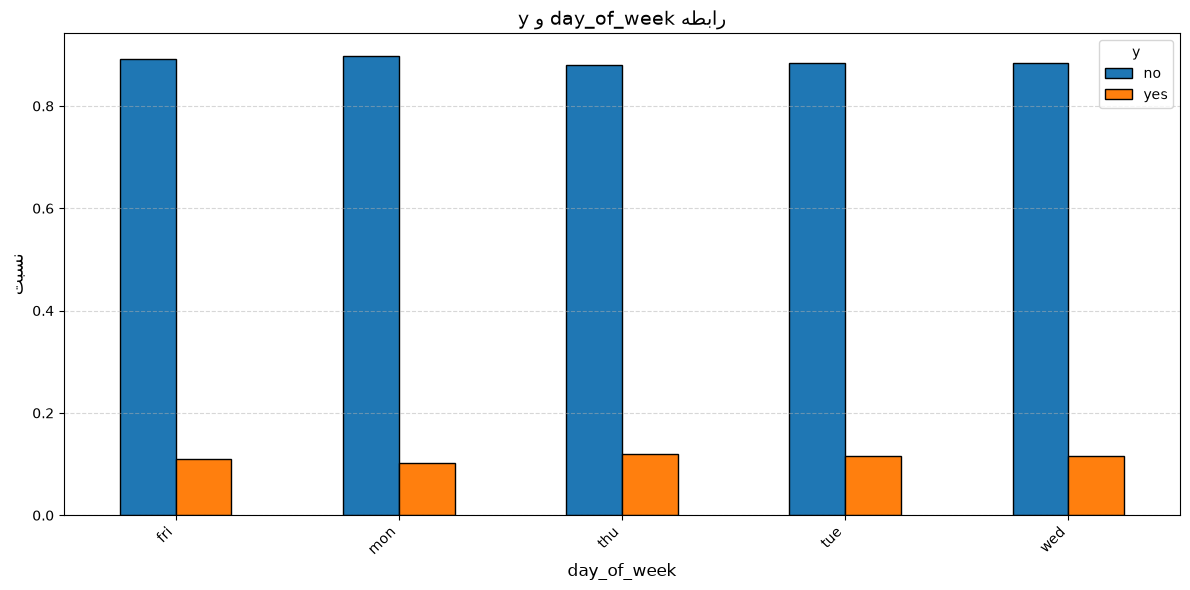

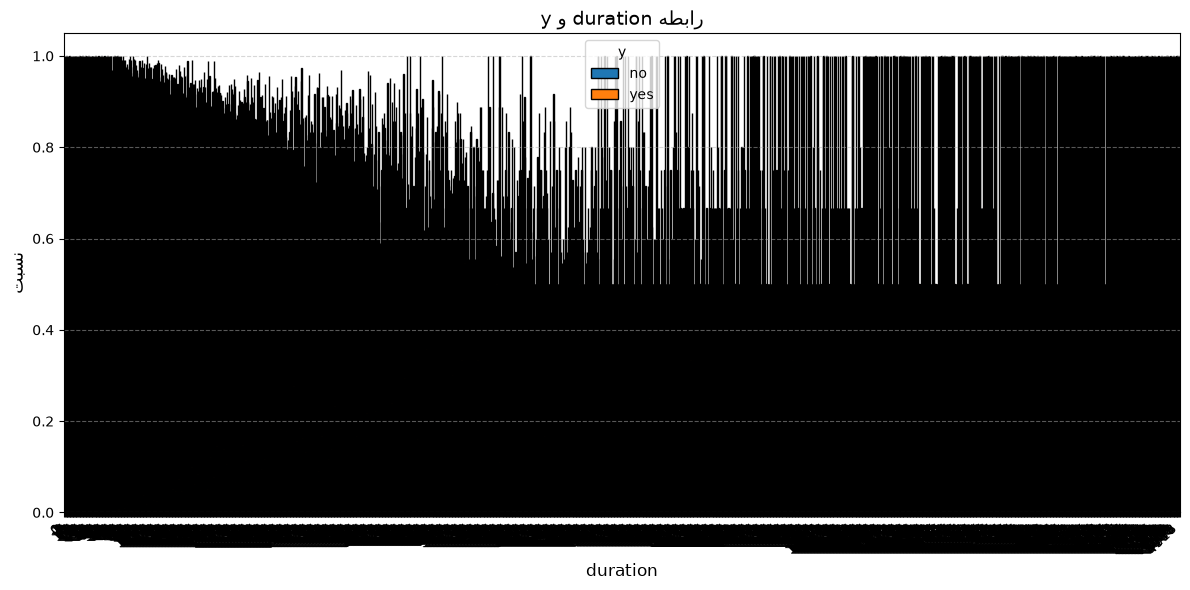

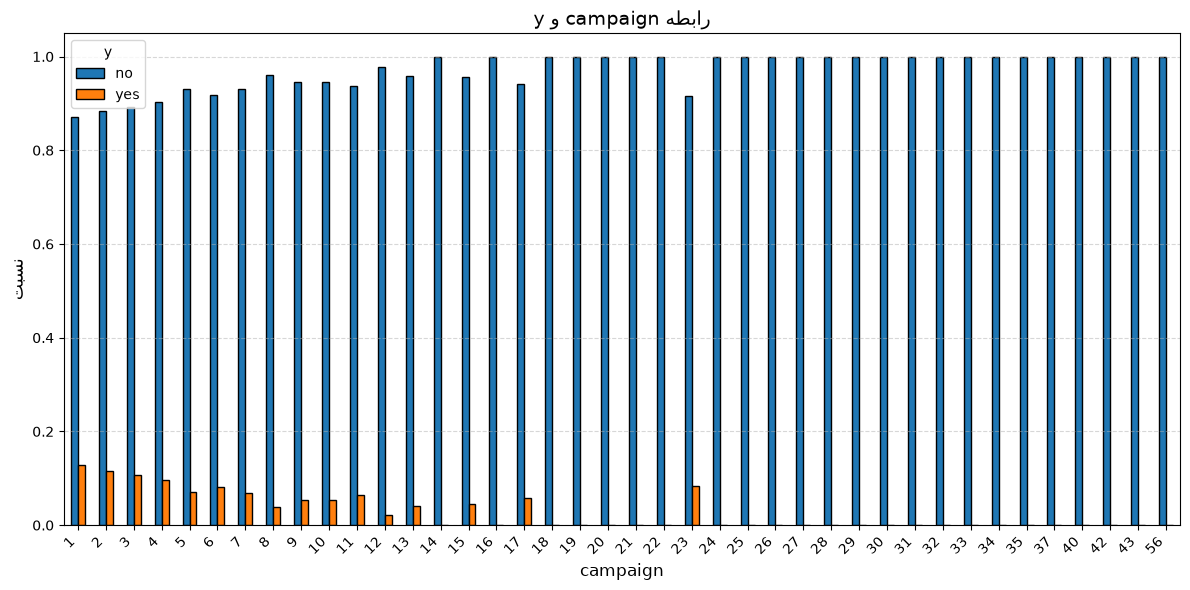

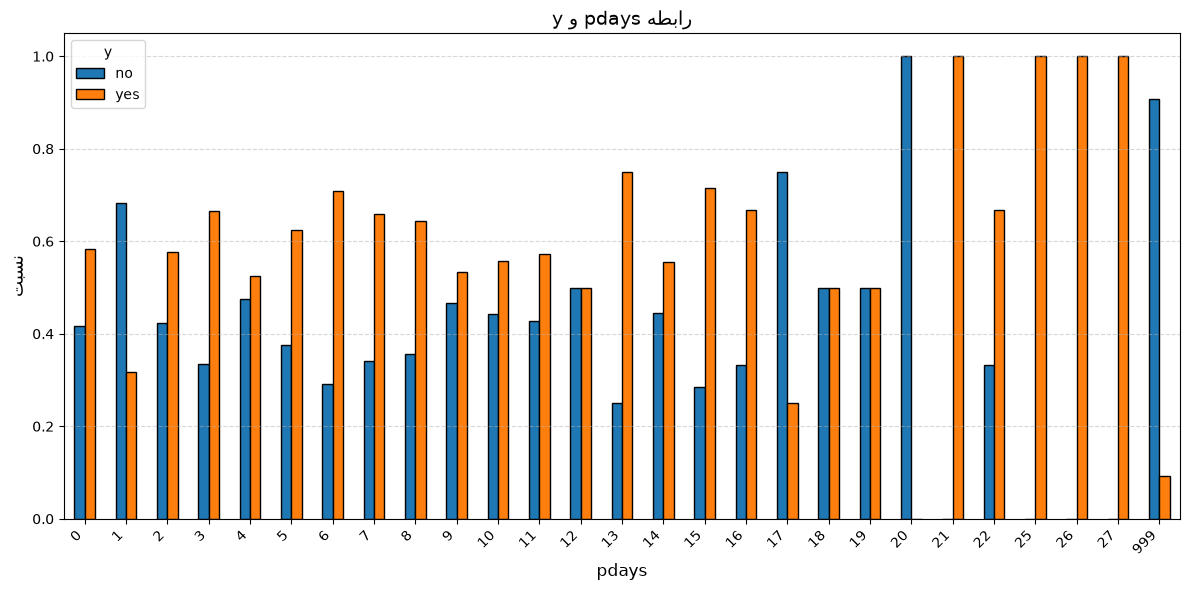

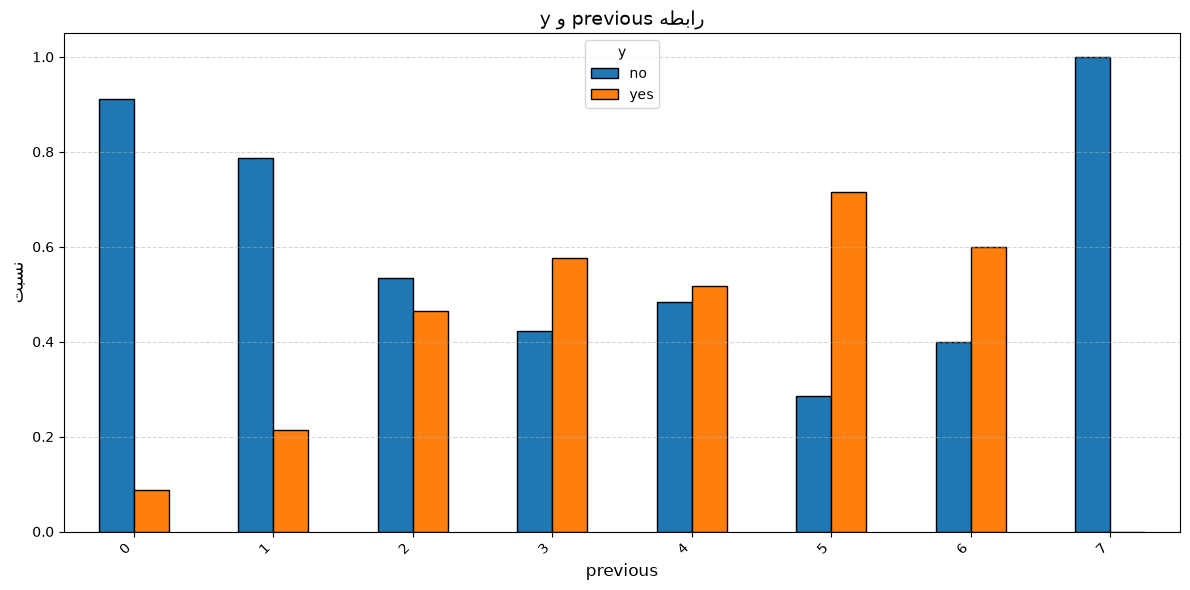

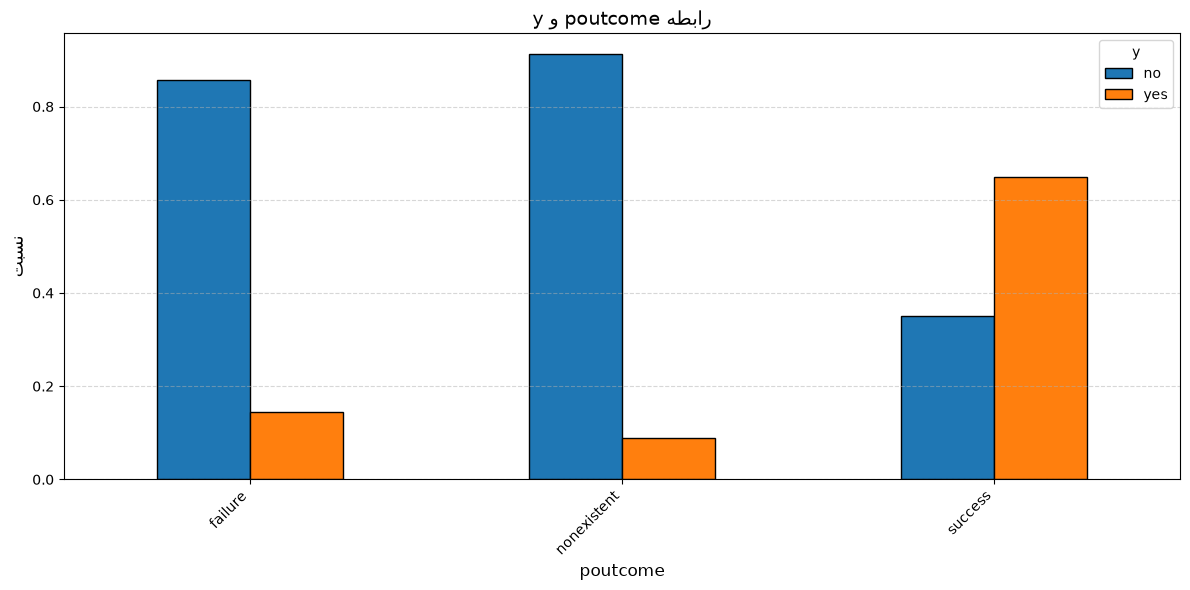

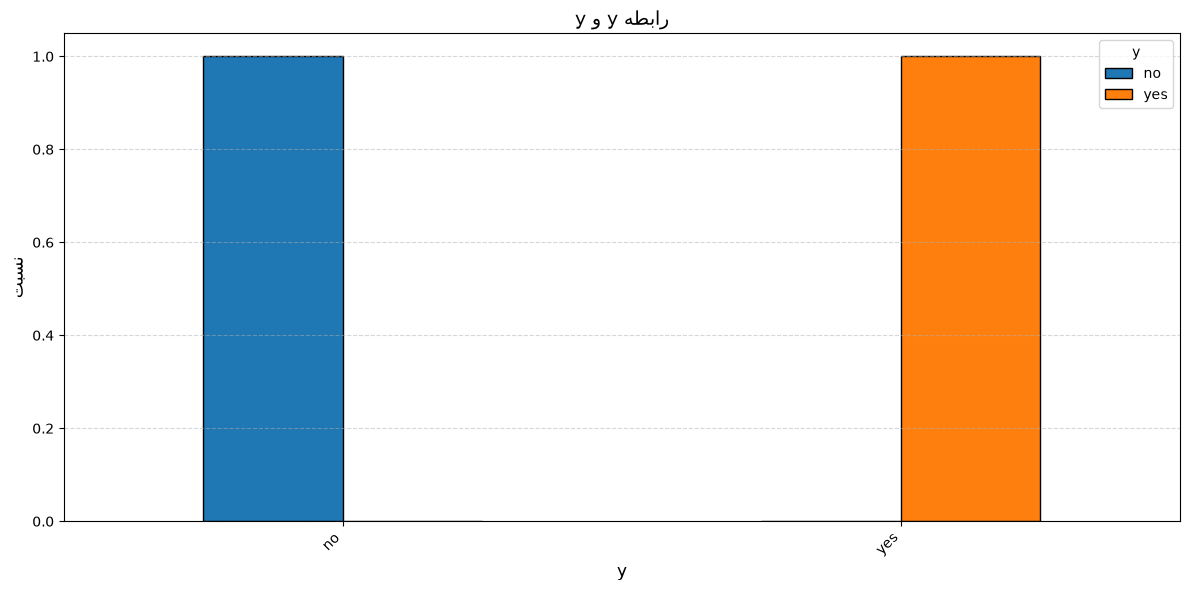

In [56]:
for col in df.columns :
    plot_cat_vs_cat(f'{col}' , 'y', df)

In [57]:
# load can be noice   # cehcj 

In [58]:
#  day of week an be noice 


In [59]:
numeric_features = [
    'age',
    'duration',
    'campaign',
    'pdays',
    'previous'
]

categorical_features = [
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan',
    'contact',
    'month',
    'day_of_week',
    'poutcome'
]

In [60]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [61]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

model = Pipeline([
    ('preprocessor', preprocessor),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

In [62]:
from sklearn.model_selection import train_test_split
# 
X = df.drop('y', axis=1)
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [63]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['no','yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','job','marital',...,'pdays','previous','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remainin

In [70]:
y_pred = model.predict(X_test)
y_pred


array(['no', 'no', 'no', ..., 'no', 'yes', 'no'],
      shape=(6590,), dtype=object)

In [69]:
from sklearn import metrics
print("Train set Accuracy: ", metrics.accuracy_score(y_train, model.predict(X_train)))
print("Test set Accuracy: ", metrics.accuracy_score(y_test, y_pred))

Train set Accuracy:  0.9231411229135054
Test set Accuracy:  0.8987860394537177


In [71]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, jaccard_score

Ks = 11

mean_acc = np.zeros(Ks - 1)
mean_jw = np.zeros(Ks - 1)
std_acc = np.zeros(Ks - 1)

for k in range(1, Ks):

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Accuracy
    mean_acc[k - 1] = accuracy_score(y_test, y_pred)

    # Jaccard
    mean_jw[k - 1] = jaccard_score(
        y_test,
        y_pred,
        average='macro',
        zero_division=0
    )

    # Standard Error
    std_acc[k - 1] = np.std(
        np.asarray(y_pred) == np.asarray(y_test)
    ) / np.sqrt(len(y_test))


# Best K
best_k = np.argmax(mean_acc) + 1

print("Best K:", best_k)
print("Best Accuracy:", mean_acc[best_k - 1])
print("Best Jaccard:", mean_jw[best_k - 1])
print("Standard Error:", std_acc[best_k - 1])

Best K: 9
Best Accuracy: 0.9036418816388467
Best Jaccard: 0.5915610910565823
Standard Error: 0.003634959895603821


In [76]:
import pandas as pd

results = pd.DataFrame({
    'K': range(1, Ks),
    'Accuracy': mean_acc,
    'Jaccard': mean_jw,
    'Standard_Error': std_acc
})

print(results)

    K  Accuracy   Jaccard  Standard_Error
0   1  0.876024  0.558212        0.004060
1   2  0.890592  0.518610        0.003845
2   3  0.893778  0.577508        0.003796
3   4  0.895296  0.540932        0.003772
4   5  0.898786  0.582933        0.003715
5   6  0.897420  0.553314        0.003738
6   7  0.899545  0.578907        0.003703
7   8  0.898634  0.557642        0.003718
8   9  0.903642  0.591561        0.003635
9  10  0.901062  0.569416        0.003678


In [74]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

model_with_k9 = Pipeline([
    ('preprocessor', preprocessor),
    ('knn', KNeighborsClassifier(n_neighbors=9))
])

In [75]:
from sklearn.model_selection import train_test_split
# 
X = df.drop('y', axis=1)
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [77]:
model_with_k9.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['no','yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','job','marital',...,'pdays','previous','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remainin

In [80]:
y_pred_k9 = model_with_k9.predict(X_test)


In [81]:
y_pred_k9

array(['no', 'no', 'no', ..., 'no', 'yes', 'no'],
      shape=(6590,), dtype=object)

In [83]:
from sklearn import metrics
print("Train set Accuracy: ", metrics.accuracy_score(y_train, model_with_k9.predict(X_train)))
print("Test set Accuracy: ", metrics.accuracy_score(y_test, y_pred_k9))

Train set Accuracy:  0.9143019726858878
Test set Accuracy:  0.9036418816388467


In [84]:
# so here check with all data 

In [85]:
# here check with all data 

In [95]:
dftrain = pd.read_csv('new_train.csv')
dftest = pd.read_csv('new_test.csv')


In [97]:
df = pd.read_csv('new_train.csv')
dftest = pd.read_csv('new_test.csv')

X_train = df.drop('y', axis=1)
y_train = df['y']

X_test = dftest

In [98]:
from sklearn.model_selection import train_test_split

X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [99]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, jaccard_score

Ks = 11

mean_acc = np.zeros(Ks - 1)
mean_jw = np.zeros(Ks - 1)
std_acc = np.zeros(Ks - 1)

for k in range(1, Ks):

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    model.fit(X_train_part, y_train_part)

    y_pred = model.predict(X_val)

    mean_acc[k-1] = accuracy_score(y_val, y_pred)

    mean_jw[k-1] = jaccard_score(
        y_val,
        y_pred,
        average='macro',
        zero_division=0
    )

    std_acc[k-1] = np.std(
        np.asarray(y_pred) == np.asarray(y_val)
    ) / np.sqrt(len(y_val))


best_k = np.argmax(mean_acc) + 1

print("Best K:", best_k)
print("Best Accuracy:", mean_acc[best_k-1])
print("Best Jaccard:", mean_jw[best_k-1])
print("Standard Error:", std_acc[best_k-1])

Best K: 9
Best Accuracy: 0.9036418816388467
Best Jaccard: 0.5915610910565823
Standard Error: 0.003634959895603821


In [101]:
from sklearn import metrics
print("Train set Accuracy: ", metrics.accuracy_score(y_train, model_with_k9.predict(dftest)))
print("Test set Accuracy: ", metrics.accuracy_score(y_test, y_pred_k9))

ValueError: columns are missing: {'pdays', 'previous'}

In [104]:
# we create knn all for datatet 
clone

NameError: name 'clone' is not defined

In [103]:
# so now we have to remove that test data and check noice 

In [121]:

def compare_features(
    X_train,
    X_val,
    y_train,
    y_val,
    preprocessor,
    drop_features=None,
    max_k=10,
    n_jobs=-1
):

    if drop_features is None:
        drop_features = []

    # Remove only existing columns
    valid_drops = [
        col for col in drop_features
        if col in X_train.columns
    ]

    X_train_new = X_train.drop(columns=valid_drops)
    X_val_new = X_val.drop(columns=valid_drops)

    # Dynamically detect remaining features
    num_cols = [
        col for col in numeric_features
        if col in X_train_new.columns
    ]

    cat_cols = [
        col for col in categorical_features
        if col in X_train_new.columns
    ]

    # Build a new preprocessor
    new_preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), num_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
        ],
        remainder='drop'
    )

    def evaluate_k(k):

        model = Pipeline([
            ('preprocessor', clone(new_preprocessor)),
            ('knn', KNeighborsClassifier(
                n_neighbors=k,
                n_jobs=1
            ))
        ])

        model.fit(X_train_new, y_train)

        y_pred = model.predict(X_val_new)

        acc = accuracy_score(y_val, y_pred)

        jac = jaccard_score(
            y_val,
            y_pred,
            average='macro',
            zero_division=0
        )

        std = np.std(
            np.asarray(y_pred) == np.asarray(y_val)
        ) / np.sqrt(len(y_val))

        return {
            'K': k,
            'Accuracy': acc,
            'Jaccard': jac,
            'Standard_Error': std
        }

    results = Parallel(
        n_jobs=n_jobs,
        prefer='threads'
    )(
        delayed(evaluate_k)(k)
        for k in range(1, max_k + 1)
    )

    result_df = pd.DataFrame(results)

    best_idx = result_df['Accuracy'].idxmax()

    print("Removed Features:", valid_drops)
    print("Best K:", result_df.loc[best_idx, 'K'])
    print("Best Accuracy:", result_df.loc[best_idx, 'Accuracy'])

    return result_df


In [122]:


from sklearn.model_selection import train_test_split



df = pd.read_csv('new_train.csv')
dftest = pd.read_csv('new_test.csv')

X_train = df.drop('y', axis=1)
y_train = df['y']

X_test = dftest
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)


In [123]:
baseline = compare_features(
    X_train_part,
    X_val,
    y_train_part,
    y_val,
    preprocessor
)
baseline

Removed Features: []
Best K: 9
Best Accuracy: 0.9036418816388467


,K,Accuracy,Jaccard,Standard_Error
0,1,0.876024,0.558212,0.004060
1,2,0.890592,0.518610,0.003845
2,3,0.893778,0.577508,0.003796
3,4,0.895296,0.540932,0.003772
4,5,0.898786,0.582933,0.003715
5,6,0.897420,0.553314,0.003738
6,7,0.899545,0.578907,0.003703
7,8,0.898634,0.557642,0.003718
8,9,0.903642,0.591561,0.003635
9,10,0.901062,0.569416,0.003678


In [126]:
without_job = compare_features(
    X_train_part,
    X_val,
    y_train_part,
    y_val,
    preprocessor,
    drop_features=['loan']
)
without_job 

Removed Features: ['loan']
Best K: 9
Best Accuracy: 0.9012139605462822


,K,Accuracy,Jaccard,Standard_Error
0,1,0.876024,0.562882,0.004060
1,2,0.890592,0.520576,0.003845
2,3,0.892109,0.574376,0.003822
3,4,0.894234,0.541466,0.003788
4,5,0.896206,0.581037,0.003757
5,6,0.897117,0.557799,0.003742
6,7,0.899697,0.584301,0.003701
7,8,0.898634,0.562066,0.003718
8,9,0.901214,0.588178,0.003676
9,10,0.898331,0.564246,0.003723


In [127]:
# this is soooooooooooooooooooooooooooooooooooo heavy 

for col in dftrain.columns :
    model_check =  compare_features(
    X_train_part,
    X_val,
    y_train_part,
    y_val,
    preprocessor,
    drop_features=[f'{col}']
)

    

SyntaxError: invalid syntax (2061992901.py, line 4)

In [128]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, jaccard_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from joblib import Parallel, delayed
import pandas as pd
import numpy as np

def compare_features(
    X_train,
    X_val,
    y_train,
    y_val,
    drop_features=None,
    max_k=10,
    n_jobs=-1
):
    drop_features = drop_features or []

    X_train_new = X_train.drop(columns=drop_features)
    X_val_new = X_val.drop(columns=drop_features)

    num_cols = [c for c in numeric_features if c in X_train_new.columns]
    cat_cols = [c for c in categorical_features if c in X_train_new.columns]

    prep = ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

    # Preprocessing فقط یک بار
    Xtr = prep.fit_transform(X_train_new)
    Xv = prep.transform(X_val_new)

    def evaluate_k(k):
        knn = KNeighborsClassifier(n_neighbors=k, n_jobs=1)
        knn.fit(Xtr, y_train)

        pred = knn.predict(Xv)

        return {
            'K': k,
            'Accuracy': accuracy_score(y_val, pred),
            'Jaccard': jaccard_score(
                y_val, pred, average='macro', zero_division=0
            )
        }

    results = Parallel(n_jobs=n_jobs, prefer='threads')(
        delayed(evaluate_k)(k)
        for k in range(1, max_k + 1)
    )

    return pd.DataFrame(results)

In [129]:
results = {}

for col in dftrain.columns.drop('y'):

    result = compare_features(
        X_train_part,
        X_val,
        y_train_part,
        y_val,
        drop_features=[col],
        n_jobs=2
    )

    results[col] = result

    print(f"\nRemoved: {col}")
    print(result)

    


Removed: age
    K  Accuracy   Jaccard
0   1  0.876024  0.559894
1   2  0.892109  0.526657
2   3  0.893171  0.579247
3   4  0.894689  0.546147
4   5  0.898027  0.581802
5   6  0.898331  0.554075
6   7  0.899545  0.578504
7   8  0.897420  0.556887
8   9  0.900455  0.581874
9  10  0.899241  0.560258

Removed: job
    K  Accuracy   Jaccard
0   1  0.877845  0.561556
1   2  0.892564  0.522767
2   3  0.894385  0.577246
3   4  0.896206  0.541599
4   5  0.897724  0.579793
5   6  0.898634  0.555843
6   7  0.901214  0.586607
7   8  0.901669  0.570293
8   9  0.904249  0.596061
9  10  0.902276  0.573777

Removed: marital
    K  Accuracy   Jaccard
0   1  0.873596  0.554153
1   2  0.892261  0.524396
2   3  0.893020  0.579028
3   4  0.893171  0.535051
4   5  0.897420  0.582447
5   6  0.895599  0.547766
6   7  0.901062  0.586374
7   8  0.899090  0.560936
8   9  0.903035  0.587819
9  10  0.900303  0.566154

Removed: education
    K  Accuracy   Jaccard
0   1  0.873596  0.558800
1   2  0.892109  0.52810

In [123]:
baseline = compare_features(
    X_train_part,
    X_val,
    y_train_part,
    y_val,
    preprocessor
)
baseline

Removed Features: []
Best K: 9
Best Accuracy: 0.9036418816388467


,K,Accuracy,Jaccard,Standard_Error
0,1,0.876024,0.558212,0.004060
1,2,0.890592,0.518610,0.003845
2,3,0.893778,0.577508,0.003796
3,4,0.895296,0.540932,0.003772
4,5,0.898786,0.582933,0.003715
5,6,0.897420,0.553314,0.003738
6,7,0.899545,0.578907,0.003703
7,8,0.898634,0.557642,0.003718
8,9,0.903642,0.591561,0.003635
9,10,0.901062,0.569416,0.003678


In [130]:
# job # default 

In [132]:
baseline3 = compare_features(
    X_train_part,
    X_val,
    y_train_part,
    y_val,
    preprocessor,
    drop_features=['job','default'],

)
baseline3

TypeError: compare_features() got multiple values for argument 'drop_features'

In [135]:
baseline3 = compare_features(
    X_train_part,
    X_val,
    y_train_part,
    y_val,
    drop_features=['job', 'default'],
    max_k=10,
    n_jobs=10
)

print(baseline3)

    K  Accuracy   Jaccard
0   1  0.878907  0.565969
1   2  0.893778  0.528092
2   3  0.895903  0.580591
3   4  0.898786  0.549138
4   5  0.899697  0.584692
5   6  0.899848  0.559753
6   7  0.900910  0.582157
7   8  0.899848  0.562432
8   9  0.903338  0.592661
9  10  0.901214  0.569635
